# HR 1 — CRISP-DM Phases 1–6: Business-to-Deployment Workshop

**Business context:** Multi-site service employer

**Problem:** Identify employees for voluntary, human-led retention review, not automatic personnel decisions.

**Proposed success criterion:** Compare with a majority-class baseline; interpret recall and precision and examine differences across departments; require HR review before any action.

**Dataset:** `hr_1.csv`. These are synthetic teaching records, not real company data.

**Submission deadline: Monday 5 October 2026 at 13:00 (1:00 PM).** Submit your completed team notebook on Brightspace. Phases 1–2 must be reviewed and updated; your main practical work is Phases 3–6. Any unfinished in-class work must be completed before the deadline.


## Phase 1 — Business Understanding and Phase 2 — Data Understanding (review)
Explain the decision, stakeholder, prediction moment, observation unit, key and target. **Review or revise the supplied success criterion if it does not adequately represent the business decision.** State two evidenced findings and two limitations.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# Work both when the notebook and CSV are together and in the course repository.
data_locations = [
    Path('hr_1.csv'),
    Path('datasets/hr_1.csv'),
    Path('/mnt/data/hr_1.csv'),
    Path('/workspaces/DATDRD05-T03---Data-science-for-business-the-CRISP-model-for-data-mining/hr_1.csv'),
]
DATA = next((path for path in data_locations if path.is_file()), None)
if DATA is None:
    raise FileNotFoundError('Place hr_1.csv beside the notebook or in datasets/.')
df = pd.read_csv(DATA)
print('Data file:', DATA)
print(df.shape)
display(df.head())
display(df.isna().sum().sort_values(ascending=False).head(12))
print('Exact duplicates:', df.duplicated().sum())

Data file: hr_1.csv
(1500, 10)


,employee_id,department,age,tenure_years,weekly_hours,overtime_flag,job_satisfaction_1_5,monthly_salary_eur,exit_interview_score_after_leaving,attrition_next_6m
0,E00000,Sales,41,14,37,0,4,4506.51,NaN,0
1,E00001,Finance,62,19,28,0,5,4939.86,NaN,0
2,E00002,Finance,25,5,43,0,5,3562.37,NaN,0
3,E00003,Finance,54,1,29,0,2,2151.15,2.0,1
4,E00004,IT,39,17,43,0,2,4316.36,NaN,0


exit_interview_score_after_leaving    1354
employee_id                              0
department                               0
age                                      0
weekly_hours                             0
tenure_years                             0
overtime_flag                            0
job_satisfaction_1_5                     0
monthly_salary_eur                       0
attrition_next_6m                        0
dtype: int64

Exact duplicates: 0


## Phase 1 & 2 — Business and Data Understanding

### Business context

The main business decision is which employees HR should review
for possible retention support.

The **Head of HR** is the main stakeholder. The prediction is made
while an employee is still employed, before HR takes action.

Each row represents **one employee**. The unique key is
`employee_id`.

The target is `attrition_next_6m`:

- `0` = employee stays for the next six months
- `1` = employee leaves within the next six months

The model should support HR decisions, not make decisions
automatically.

### Success criterion

Accuracy alone does not adequately represent the business decision.

**Recall** is important because HR wants to identify employees who
actually leave. A false negative means that an employee who leaves
was not identified for review.

**Precision** is also important because too many false positives
would cause HR to review employees who would not have left.

Therefore, recall and precision for `attrition_next_6m = 1` should
be used to evaluate the model.

### Evidenced findings

1. The dataset contains **1,500 employees and 10 variables**.
   `employee_id` has no missing values and can be used as the
   unique employee key.

2. `exit_interview_score_after_leaving` has **1,354 missing values**.
   This variable is collected after an employee leaves and is not
   available at the prediction moment. It should therefore not be
   used as a predictor.

### Limitations

1. Relationships in this dataset show associations, not causation.
   The analysis cannot prove that factors such as overtime, salary
   or job satisfaction cause attrition.

2. The dataset contains a limited number of employee characteristics.
   Other factors that may influence attrition are not included.
   HR should therefore review model results before taking action.

## Phase 3 — Data Preparation: three justified decisions
For EACH insight: evidence → technique → before/after verification → interpretation → next decision. Consider identifiers, leakage, duplicate keys, suspicious values, categories, date parsing and feature engineering. Explain why you retain, delete or combine variables. **Do not use the target or post-outcome fields as predictors.**

In [2]:
# Add your preparation code below. Inspect before/after evidence.
# Make a copy first:
import pandas as pd

# Load dataset
df = pd.read_csv(DATA)

# Make a working copy
work = df.copy()

print("Dataset loaded:", df.shape)


# ============================================================
# Decision 1 — Remove employee identifier
# ============================================================

print("\nDECISION 1 — EMPLOYEE IDENTIFIER")

print("Unique employee IDs:", work["employee_id"].nunique())
print("Number of rows:", len(work))
print("Duplicate employee IDs:",
      work["employee_id"].duplicated().sum())

print("Before removal:",
      "employee_id" in work.columns)

work = work.drop(columns=["employee_id"])

print("After removal:",
      "employee_id" in work.columns)


# ============================================================
# Decision 2 — Remove post-outcome information
# ============================================================

print("\nDECISION 2 — POST-OUTCOME INFORMATION")

print("Missing exit interview scores:",
      work["exit_interview_score_after_leaving"].isna().sum())

print("Before removal:",
      "exit_interview_score_after_leaving" in work.columns)

work = work.drop(
    columns=["exit_interview_score_after_leaving"]
)

print("After removal:",
      "exit_interview_score_after_leaving" in work.columns)


# ============================================================
# Decision 3 — Check remaining predictor quality
# ============================================================

print("\nDECISION 3 — PREDICTOR QUALITY")

print("Duplicate rows:", work.duplicated().sum())

print("\nMissing values:")
print(work.isna().sum())

numeric_columns = [
    "age",
    "tenure_years",
    "weekly_hours",
    "overtime_flag",
    "job_satisfaction_1_5",
    "monthly_salary_eur"
]

print("\nNumeric ranges:")
print(work[numeric_columns].describe().T)

print("\nDepartment categories:")
print(work["department"].value_counts())


# ============================================================
# Final predictor and target check
# ============================================================

target = "attrition_next_6m"

predictors = [
    column for column in work.columns
    if column != target
]

print("\nTarget:", target)
print("Predictors:", predictors)
print("Target used as predictor:",
      target in predictors)

Dataset loaded: (1500, 10)

DECISION 1 — EMPLOYEE IDENTIFIER
Unique employee IDs: 1500
Number of rows: 1500
Duplicate employee IDs: 0
Before removal: True
After removal: False

DECISION 2 — POST-OUTCOME INFORMATION
Missing exit interview scores: 1354
Before removal: True
After removal: False

DECISION 3 — PREDICTOR QUALITY
Duplicate rows: 0

Missing values:
department              0
age                     0
tenure_years            0
weekly_hours            0
overtime_flag           0
job_satisfaction_1_5    0
monthly_salary_eur      0
attrition_next_6m       0
dtype: int64

Numeric ranges:
                       count         mean  ...       75%     max
age                   1500.0    40.538667  ...    50.250    62.0
tenure_years          1500.0    10.982000  ...    17.000    22.0
weekly_hours          1500.0    43.353333  ...    51.000    58.0
overtime_flag         1500.0     0.566667  ...     1.000     1.0
job_satisfaction_1_5  1500.0     3.034000  ...     4.000     5.0
monthly_sala

## Preparation decisions

### Decision 1 — Remove the employee identifier

**Evidence:** The dataset contains 1,500 rows and 1,500 unique
employee IDs, with 0 duplicate IDs.

**Technique:** `employee_id` was removed from the modelling data.

**Verification:** The variable was present before removal (`True`)
and absent afterwards (`False`).

**Interpretation:** `employee_id` uniquely identifies employees,
but does not represent an employee characteristic that should be
used to predict attrition.

**Next decision:** Continue with variables that are meaningful
and available at the prediction moment.


### Decision 2 — Remove post-outcome information

**Evidence:** `exit_interview_score_after_leaving` contains 1,354
missing values and is only available after an employee has left.

**Technique:** The variable was removed to prevent data leakage.

**Verification:** The variable was present before removal (`True`)
and absent afterwards (`False`).

**Interpretation:** Exit interview information is not available
when HR makes the prediction. Using it as a predictor would cause
data leakage.

**Next decision:** Only information available at the prediction
moment will be used as predictors.


### Decision 3 — Retain valid predictors

**Evidence:** The prepared data contains 0 duplicate rows and
0 missing values in all remaining variables. Numeric ranges and
department categories were also inspected.

**Technique:** The remaining predictors were checked for data
quality before modelling.

**Verification:** No duplicate rows or missing values were found.
The final predictors are `department`, `age`, `tenure_years`,
`weekly_hours`, `overtime_flag`, `job_satisfaction_1_5` and
`monthly_salary_eur`.

**Interpretation:** There is no evidence from these checks that
the remaining variables need to be deleted. `department` is a
categorical variable and can be encoded when required by the model.

**Next decision:** Retain these variables for modelling.
`attrition_next_6m` remains the target only and is not used as
a predictor.

### Preparation decision log
### Preparation decision log

| Phase 2 finding | Technique and reason | Verification | Risk | Next decision |
|---|---|---|---|---|
| `employee_id` is a unique identifier | Remove it because it has no predictive meaning | 1,500 unique IDs and 0 duplicate IDs | Identifier misuse | Exclude from predictors |
| Exit interview data is post-outcome | Remove it to prevent data leakage | Column is absent after removal | Data leakage | Use only pre-outcome predictors |
| Remaining predictors require quality checks | Check duplicates, missing values, ranges and categories | Inspect results before modelling | Invalid or suspicious data | Retain valid predictors and encode when needed |

## Phase 4 — Modelling

### Business decision, target and prediction moment
- **Decision:** support the Head of HR in selecting employees for a *voluntary, human-led retention review*, never an automatic employment or personnel action.
- **Observation/key:** one employee at the survey date; `employee_id` uniquely identifies a record, but is not a model input.
- **Prediction moment:** at the employee survey, **before** the following six months and before a possible exit interview.
- **Target:** `attrition_next_6m` (1 = leaves within six months; 0 = stays). The data does not tell us whether every recorded departure was voluntary, so this is a proxy for the proposed voluntary-retention decision.
- **Eligible survey-time fields:** `department`, `age`, `tenure_years`, `weekly_hours`, `overtime_flag`, `job_satisfaction_1_5`, `monthly_salary_eur`. Their operational availability must be confirmed by HR before a real pilot. `department` is retained for comparison but must also be checked for unintended disparities.
- **Feature engineering:** add `overtime_hours_interaction = weekly_hours × overtime_flag`, capturing weekly hours specifically when overtime is reported. The original two fields are retained; we check whether the engineered feature adds value in *training-only* cross-validation.
- **Excluded:** `employee_id` (identifier), `exit_interview_score_after_leaving` (post-outcome information and therefore leakage), and the target itself. We explicitly assert this below.

### Split, baseline, candidate and safeguards

Use one **stratified 80/20 held-out employee split** (`random_state=42`). This is defensible for this teaching classification case because every `employee_id` appears once. A chronological split cannot be constructed: there is no survey date field. A future operational assessment **must** use a later cohort or a truly prospective test.

| Comparison | Choice | Why it fits the decision |
|---|---|---|
| Simple baseline | `DummyClassifier(strategy='most_frequent')`, i.e. predict that every employee stays | Reproduces the majority-class policy, makes the misleadingly high accuracy visible, and recalls no actual departures. |
| Candidate | Class-weighted **logistic regression** with one-hot encoded department and scaled numeric fields | Provides repeatable risk rankings and relatively interpretable associations without claiming causality; class weighting acknowledges that departures are uncommon. |
| Learning/preparation | `SimpleImputer`, `StandardScaler`, `OneHotEncoder(handle_unknown='ignore')` **inside an sklearn `Pipeline`** | Their learned values are fitted only from the training fold; held-out rows do not influence preprocessing or model training. |
| Test method | Single untouched stratified test set; training-only 5-fold CV to compare features | Report true held-out results, including precision, recall and false positives/negatives. The CV feature comparison is exploratory, not a licence to optimise against the test set. |

**Review-capacity scenario:** the case brief provides no numerical HR capacity. For illustration only, we evaluate reviewing the 10% highest-scored test employees (also show 5% and 15% sensitivity). **10% is an exercise assumption, not a verified company target.** A 0.50 probability cut-off is reported as a diagnostic, not prescribed as a real HR policy.


In [3]:
# Phase 4 — modelling: baseline, leakage checks, engineered workload, held-out test
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

source_df = df.copy()  # the original file, before Phase 3 dropped columns
TARGET = 'attrition_next_6m'
KEY = 'employee_id'
LEAKAGE_FIELD = 'exit_interview_score_after_leaving'
base_features = [
    'department', 'age', 'tenure_years', 'weekly_hours', 'overtime_flag',
    'job_satisfaction_1_5', 'monthly_salary_eur'
]
engineered_feature = 'overtime_hours_interaction'
all_features = base_features + [engineered_feature]

# A row represents one employee in this supplied survey data.
assert source_df[KEY].notna().all() and source_df[KEY].is_unique, 'Investigate duplicate/missing employee IDs before splitting.'
assert source_df[TARGET].notna().all() and set(source_df[TARGET].unique()) <= {0, 1}
assert not set([KEY, LEAKAGE_FIELD, TARGET]).intersection(all_features), 'Leakage or identifiers included in features.'
X = source_df[base_features].copy()
X[engineered_feature] = X['weekly_hours'] * X['overtime_flag']
y = source_df[TARGET].astype(int)

print('Employees:', len(X), '| observed departures:', int(y.sum()),
      '| overall departure rate: {:.1%}'.format(y.mean()))
print('Unique employee IDs:', source_df[KEY].nunique())
print('Excluded from modelling:', [KEY, LEAKAGE_FIELD, TARGET])
print('Engineered example (hours × overtime flag):')
display(X[['weekly_hours', 'overtime_flag', engineered_feature]].head())
print('Missing eligible values:', int(X.isna().sum().sum()))

# Random stratified split is appropriate only for this one-row-per-employee exercise.
# No survey timestamps exist for a chronological test; request them for a real pilot.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
assert X_train.index.intersection(X_test.index).empty
print('Train: {} people, {} departed ({:.1%}); test: {} people, {} departed ({:.1%})'.format(
    len(X_train), int(y_train.sum()), y_train.mean(),
    len(X_test), int(y_test.sum()), y_test.mean()
))

def build_candidate(input_columns):
    numeric_columns = [column for column in input_columns if column != 'department']
    categorical_columns = ['department'] if 'department' in input_columns else []
    numeric_pipeline = Pipeline([
        ('fill_missing', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ('fill_missing', SimpleImputer(strategy='most_frequent')),
        ('one_hot', OneHotEncoder(handle_unknown='ignore')),
    ])
    preparation = ColumnTransformer([
        ('numeric', numeric_pipeline, numeric_columns),
        ('category', categorical_pipeline, categorical_columns),
    ], remainder='drop')
    return Pipeline([
        ('prepare', preparation),
        ('classify', LogisticRegression(class_weight='balanced', max_iter=2000,
                                        random_state=42)),
    ])

# Compare original versus engineered predictors on TRAINING FOLDS ONLY.
# Each fold fits its imputer, encoder, scaler and classifier without validation-fold data.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for label, columns in [('Original eligible features', base_features),
                       ('With workload interaction', all_features)]:
    cv_probabilities = cross_val_predict(
        build_candidate(columns), X_train[columns], y_train,
        cv=cv, method='predict_proba'
    )[:, 1]
    cv_rows.append({
        'training-only feature set': label,
        'out-of-fold average precision': average_precision_score(y_train, cv_probabilities),
    })
cv_results = pd.DataFrame(cv_rows)
print('5-fold training-only feature comparison (higher AP is preferable):')
display(cv_results.round(4))

baseline_model = DummyClassifier(strategy='most_frequent')
baseline_model.fit(X_train[all_features], y_train)
# Candidate was specified above; the engineered feature is retained as a teaching example.
candidate_model = build_candidate(all_features)
candidate_model.fit(X_train[all_features], y_train)

# Only now compute untouched held-out predictions. Values are reused in Phase 5.
baseline_prediction = baseline_model.predict(X_test[all_features])
candidate_probability = candidate_model.predict_proba(X_test[all_features])[:, 1]
candidate_prediction_05 = (candidate_probability >= 0.50).astype(int)
print('Both models trained only on training rows; test predictions are ready for Phase 5.')


Employees: 1500 | observed departures: 146 | overall departure rate: 9.7%
Unique employee IDs: 1500
Excluded from modelling: ['employee_id', 'exit_interview_score_after_leaving', 'attrition_next_6m']
Engineered example (hours × overtime flag):


,weekly_hours,overtime_flag,overtime_hours_interaction
0,37,0,0
1,28,0,0
2,43,0,0
3,29,0,0
4,43,0,0


Missing eligible values: 0
Train: 1200 people, 117 departed (9.8%); test: 300 people, 29 departed (9.7%)
5-fold training-only feature comparison (higher AP is preferable):


,training-only feature set,out-of-fold average precision
0,Original eligible features,0.1404
1,With workload interaction,0.1407


Both models trained only on training rows; test predictions are ready for Phase 5.


## Phase 5 — Business Evaluation

**Revised Phase 1 evaluation question:** Can a model help HR prioritise *human-led* retention reviews, compared with the majority-class baseline, while delivering useful **recall and precision within a realistic review capacity and without unexplained department-level disparities**? The original brief gives no agreed threshold for acceptable recall, precision, departmental differences, HR capacity or business cost. Therefore this notebook reports evidence for a decision, **not a verified pass against an invented threshold**.

The code below shows (a) baseline and candidate at a 0.50 cut-off, (b) the candidate when HR could review the *top 10%* of scores as a **hypothetical** capacity scenario, (c) 5%/10%/15% sensitivity and (d) review and error differences by department. False negatives are departing employees who were not selected; false positives are employees selected for review who would otherwise have stayed. Neither outcome establishes the effect of retention contact, and nobody should face adverse action because of a score.


HELD-OUT TEST COMPARISON | Positive class = departure within next six months


,reviewed / flagged,test accuracy,precision (leavers),recall (leavers),F1 (leavers),TN,FP,FN,TP
method,,,,,,,,,
Majority baseline: predict stays,0,0.903,0.000,0.000,0.000,271,0,29,0
Candidate: 0.50 cut-off,128,0.590,0.133,0.586,0.217,160,111,12,17
Candidate: top 10% reviewed (illustrative),30,0.823,0.100,0.103,0.102,244,27,26,3


Interpret precision=0 for the baseline as no employee flagged (no positive predictions).
Confusion matrix rows = actual [stays, leaves], columns = prediction [stays, review]:
Majority-class baseline 
 [[271   0]
 [ 29   0]]
Logistic candidate at 0.50 
 [[160 111]
 [ 12  17]]
Logistic candidate: top 10% scenario 
 [[244  27]
 [ 26   3]]
RANKING METRICS | Candidate, untouched held-out test
Average precision (PR-AUC): 0.125 | ROC-AUC: 0.592 | Test prevalence: 0.097
CAPACITY SENSITIVITY (not policy recommendations or test-set optimisation):


,illustrative capacity,reviewed,correctly flagged (TP),unnecessary reviews (FP),missed leavers (FN),precision,recall
0,5%,15,1,14,28,0.067,0.034
1,10%,30,3,27,26,0.100,0.103
2,15%,45,7,38,22,0.156,0.241


DEPARTMENT BREAKDOWN — top 10% global review scenario (NaN precision = nobody selected):


,n in test,actual departures,observed departure rate,selected for review,review selection rate,true positives,false positives,false negatives,precision,recall
department,,,,,,,,,,
Finance,57,6,0.105,5,0.088,1,4,5,0.200,0.167
HR,62,6,0.097,11,0.177,1,10,5,0.091,0.167
IT,57,5,0.088,4,0.070,0,4,5,0.000,0.000
Operations,67,7,0.104,10,0.149,1,9,6,0.100,0.143
Sales,57,5,0.088,0,0.000,0,0,5,NaN,0.000


At a random 10% review allocation, expected TP using test prevalence ≈ 2.90; candidate TP = 3.


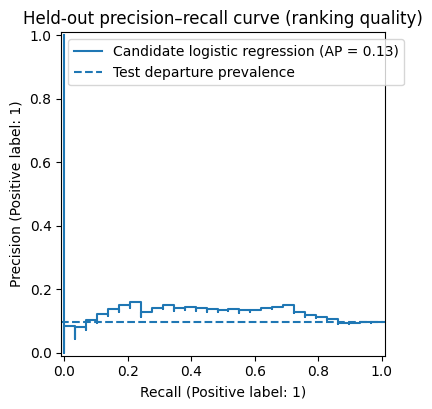

In [4]:
# Phase 5 — evaluation on the held-out test group ONLY
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, average_precision_score, roc_auc_score,
    PrecisionRecallDisplay
)
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', None)

# This rule ranks by TRAINED model score; it does not choose the cut-off using test outcomes.
def top_fraction_review(probabilities, fraction):
    n = len(probabilities)
    k = int(np.ceil(n * fraction))
    selected = np.zeros(n, dtype=int)
    selected[np.argsort(-np.asarray(probabilities), kind='stable')[:k]] = 1
    return selected

# This is a teaching scenario, not an HR-provided or optimised capacity target.
illustrative_capacity = 0.10
candidate_review_10pct = top_fraction_review(candidate_probability, illustrative_capacity)

def score_errors(y_true, prediction):
    tn, fp, fn, tp = confusion_matrix(y_true, prediction, labels=[0, 1]).ravel()
    return {
        'reviewed / flagged': int(tp + fp),
        'test accuracy': accuracy_score(y_true, prediction),
        'precision (leavers)': precision_score(y_true, prediction, zero_division=0),
        'recall (leavers)': recall_score(y_true, prediction, zero_division=0),
        'F1 (leavers)': f1_score(y_true, prediction, zero_division=0),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
    }

comparisons = pd.DataFrame([
    {'method': 'Majority baseline: predict stays', **score_errors(y_test, baseline_prediction)},
    {'method': 'Candidate: 0.50 cut-off', **score_errors(y_test, candidate_prediction_05)},
    {'method': 'Candidate: top 10% reviewed (illustrative)',
     **score_errors(y_test, candidate_review_10pct)},
]).set_index('method')
print('HELD-OUT TEST COMPARISON | Positive class = departure within next six months')
display(comparisons.round(3))
print('Interpret precision=0 for the baseline as no employee flagged (no positive predictions).')

print('Confusion matrix rows = actual [stays, leaves], columns = prediction [stays, review]:')
for name, decision in [
    ('Majority-class baseline', baseline_prediction),
    ('Logistic candidate at 0.50', candidate_prediction_05),
    ('Logistic candidate: top 10% scenario', candidate_review_10pct)
]:
    print(name, '\n', confusion_matrix(y_test, decision, labels=[0, 1]))

print('RANKING METRICS | Candidate, untouched held-out test')
print('Average precision (PR-AUC): {:.3f} | ROC-AUC: {:.3f} | Test prevalence: {:.3f}'.format(
    average_precision_score(y_test, candidate_probability),
    roc_auc_score(y_test, candidate_probability), y_test.mean()
))

capacity_rows = []
for fraction in (0.05, 0.10, 0.15):
    decision = top_fraction_review(candidate_probability, fraction)
    entry = score_errors(y_test, decision)
    capacity_rows.append({
        'illustrative capacity': '{:.0%}'.format(fraction),
        'reviewed': entry['reviewed / flagged'],
        'correctly flagged (TP)': entry['TP'],
        'unnecessary reviews (FP)': entry['FP'],
        'missed leavers (FN)': entry['FN'],
        'precision': entry['precision (leavers)'],
        'recall': entry['recall (leavers)']
    })
print('CAPACITY SENSITIVITY (not policy recommendations or test-set optimisation):')
display(pd.DataFrame(capacity_rows).round(3))

# Department-level inspection of the same global top-10%-of-test policy.
# These are small teaching-case groups, not conclusions about protected-class fairness.
test_report = pd.DataFrame({
    'department': X_test['department'].to_numpy(),
    'actually_departed': y_test.to_numpy(),
    'selected_for_review': candidate_review_10pct,
    'model_score': candidate_probability
})
department_rows = []
for dept, part in test_report.groupby('department', sort=True):
    count = len(part)
    actual = int(part['actually_departed'].sum())
    reviewed = int(part['selected_for_review'].sum())
    tp = int(((part['actually_departed'] == 1) &
              (part['selected_for_review'] == 1)).sum())
    department_rows.append({
        'department': dept, 'n in test': count,
        'actual departures': actual,
        'observed departure rate': actual / count,
        'selected for review': reviewed,
        'review selection rate': reviewed / count,
        'true positives': tp,
        'false positives': reviewed - tp,
        'false negatives': actual - tp,
        'precision': tp / reviewed if reviewed else np.nan,
        'recall': tp / actual if actual else np.nan,
    })
department_results = pd.DataFrame(department_rows).set_index('department')
print('DEPARTMENT BREAKDOWN — top 10% global review scenario (NaN precision = nobody selected):')
display(department_results.round(3))

# A no-model random 10% review would identify approximately the observed prevalence
# times 30 people IN EXPECTATION, not necessarily in any particular random draw.
number_reviewed = int(candidate_review_10pct.sum())
print('At a random 10% review allocation, expected TP using test prevalence ≈ {:.2f}; candidate TP = {}.'.format(
    number_reviewed * y_test.mean(),
    score_errors(y_test, candidate_review_10pct)['TP']
))

fig, ax = plt.subplots(figsize=(7.0, 4.2))
PrecisionRecallDisplay.from_predictions(y_test, candidate_probability, ax=ax,
                                       name='Candidate logistic regression')
ax.axhline(y_test.mean(), linestyle='--', label='Test departure prevalence')
ax.set_title('Held-out precision–recall curve (ranking quality)')
ax.legend(loc='best')
plt.show()


### Evidence-based interpretation and next decision

**1. What improved over the baseline?** In the held-out **300 employees**, 29 actually leave within six months (9.7%). Predicting *everyone stays* (majority baseline) obtains **90.3% accuracy but 0% recall**: it misses all 29 departures and initiates no reviews. The logistic-regression candidate at the standard **0.50 cut-off** correctly flags **17** departing employees (**58.6% recall**), but also flags **111** employees who stay. Its **precision is 13.3%**, and HR would be asked to review **128/300 employees (42.7%)**. Higher recall alone therefore does not establish that this is an acceptable workflow.

**2. What if review time is limited?** Neither the brief nor the dataset gives actual HR review capacity, so we use **10% only as an explicitly hypothetical scenario**. Reviewing the top **30/300** model scores identifies **3 true departures**, triggers **27 reviews of employees who stayed**, and misses **26 departures**: **precision 10.0%** and **recall 10.3%**. Given the observed test departure prevalence (9.7%), selecting 30 people uniformly at random would identify about **2.9 departures in expectation**. Thus, in this capacity example, the model's observed top-30 outcome offers little evidence of useful prioritisation beyond chance. For transparency, the code also evaluates 5% and 15% capacities; it does not choose the best-performing option after looking at the test outcomes. None of these percentages is an approved organisational target.

**3. Which error matters most?** A **false negative** represents a missed chance to consider retention support for someone who leaves. A **false positive** consumes scarce HR time and could subject an employee to unwanted attention. The case provides no costs per review, cost of avoidable departures, or evidence that reaching out prevents departures. Their comparative business cost therefore **cannot be ranked or monetised from these data**. HR must set an acceptable contact capacity, minimum recall/precision, escalation rules and voluntary participation safeguards before success can be judged.

**4. Check department differences:** With the single global top-10% policy, Finance receives **5 reviews (1 true departure)**, HR **11 (1)**, IT **4 (0)**, Operations **10 (1)** and Sales **0 (0)**. Yet **five Sales employees actually leave** in the test sample. The uneven selection and missed departures warrant investigation, but small test subgroups cannot prove systematic unfairness. A real evaluation should review subgroup coverage, possible proxy effects from `department` and `age`, and data quality with HR; no score should drive an automatic personnel action.

**5. Did preparation choices help?** Removing `employee_id` prevents meaningless key-based predictions; removing `exit_interview_score_after_leaving` is **mandatory to prevent target leakage** (that value is only known after leaving). Training-only 5-fold average precision is **0.1404** with the original eligible features versus **0.1407** after adding `overtime_hours_interaction`, so there is **no material measured benefit** from the engineered feature in this experiment. This avoids overstating a small numeric difference. No discovered association establishes that a feature *causes* departure.

**6. Evaluate against revised Phase 1:** The brief requires comparison with the majority baseline, precision/recall, department differences and human-led review, but supplies **no quantified capacity or approved performance threshold**. We can meet its *reporting* requirements, not certify a business-success target. We also lack survey timestamps for an out-of-time validation, a verified *voluntary*-leaving indicator (the provided target records departure, not stated reason), evidence of predictor availability at survey time, intervention outcomes, costs and retention benefits. Claimed savings or attrition reduction would be invented.

**Group decision supported by this phase: obtain missing data and improve the model; not ready for operational deployment or real employee targeting.** Return to **Phase 1** to agree HR capacity, success/cost criteria and safeguards; **Phase 2–3** for dates, voluntary-departure labels, timestamped predictors and intervention outcomes; and **Phase 4–5** for prospective, out-of-time validation, comparison with a capacity-matched non-model approach, and review of departmental disparities. An eventual pilot would still need transparent human review, appropriate privacy safeguards and no automated adverse decisions. This recommendation applies to the model/workflow, never to an individual employee.


## Phase 6 — Deployment proposal (design only)
# Phase 6 – Deployment Proposal (Design Only)

## 6.1 Deployment Workflow

The model is intended to support HR and will not make
automatic personnel decisions.

The proposed workflow is:

**Employee data → Data preparation → Attrition prediction →
HR review → Voluntary retention action → Outcome recording →
Model monitoring**

HR is responsible for reviewing employees identified by
the model before any action is taken.

The model could be run periodically when new employee
survey data becomes available. Employees with higher
predicted attrition risk can be considered for a voluntary
retention review.

HR always has the ability to override the model prediction.
A prediction alone must never result in an automatic
personnel decision.


## 6.2 Monitoring and Fairness

Precision and recall should be monitored after deployment.

Performance and selection rates should also be compared
across departments to detect possible fairness problems.

The model should be reviewed when new employee and
attrition outcomes become available.

Use of the model should be paused if performance drops
substantially or if large unexplained differences between
departments are detected.


## 6.3 Privacy and Human Oversight

Only employee information necessary for the prediction
should be used.

Predictions should only be accessible to authorised
HR employees.

The model provides decision support only.
Final decisions and any retention actions remain the
responsibility of HR.


## Phase 6 Conclusion

Based on the current evaluation, the model is not ready
for operational deployment.

Additional data and further model improvement are required
before a controlled pilot should be considered.

## Final group decision + individual accountability
# Final Group Decision + Individual Accountability

## Group Decision

Our recommendation is to **not deploy the model yet**.

The logistic regression model improves recall compared with
the majority-class baseline, but precision remains low.

At the standard threshold, the model identified 17 of the
29 employees who left, but it also produced 111 false
positives.

Under the hypothetical 10% HR review capacity, the model
identified only 3 of the 29 employees who actually left.

There were also differences in selection across departments
that require further investigation.

The group therefore recommends improving the model and
obtaining additional data before considering a controlled
pilot.


## Individual Accountability – Yorick Kempers

One important preparation choice was excluding
`exit_interview_score_after_leaving`, because this information
is only available after an employee has left and would cause
data leakage.

An important model finding was that the logistic regression
achieved a recall of 58.6%, identifying 17 of the 29 employees
who actually left. However, precision was only 13.3%, resulting
in many false positives.

From a business perspective, this means the model can identify
more potential leavers than the majority-class baseline, but
HR would need to review too many employees for the current
model to be practically useful.

My decision is therefore to improve and validate the model
before deployment.

A remaining limitation is that the dataset does not contain
verified information about HR review capacity, the costs of
prediction errors or whether retention actions actually
prevent employees from leaving.